# ChurnGuard: Customer Churn Prediction and Retention Support System

Run the cells from top to bottom. Use a CPU runtime (Runtime, Change runtime type, CPU).

Steps: 1 setup, 2 data, 3 train, 4 results, 5 explanations, 6 API demo, 7 tests, 8 extras.

## 1. Setup

In [9]:
import os, sys

PROJECT = os.getcwd()
if PROJECT not in sys.path:
    sys.path.insert(0, PROJECT)
print("Working folder:", PROJECT)
print(sorted(os.listdir(".")))

Working folder: c:\Users\HP 840 G5\OneDrive\Desktop\zaid .html\ChurnGuard
['.dockerignore', '.env.example', '.gitignore', 'ARCHITECTURE.md', 'ChurnGuard_Colab.ipynb', 'Dockerfile', 'MONITORING_NOTES.md', 'README.md', 'app', 'churnguard', 'data', 'frontend', 'logs', 'models', 'pytest.ini', 'reports', 'requirements-api.txt', 'requirements.txt', 'run_all.bat', 'run_all.sh', 'tests']


In [10]:
!pip install -q -r requirements.txt


[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: C:\Users\HP 840 G5\AppData\Local\Programs\Python\Python312\python.exe -m pip install --upgrade pip


## 2. Data

The Telco Customer Churn dataset is already inside the project (`data/`).

In [11]:
import pandas as pd
from churnguard import data, config

raw = data.load_raw()
print(raw.shape)
display(raw.head())
frame = data.clean(raw)
print("Churn rate:", round(frame["Churn"].mean(), 4))
print("Missing values after cleaning:", int(frame.isna().sum().sum()))

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Churn rate: 0.2654
Missing values after cleaning: 0


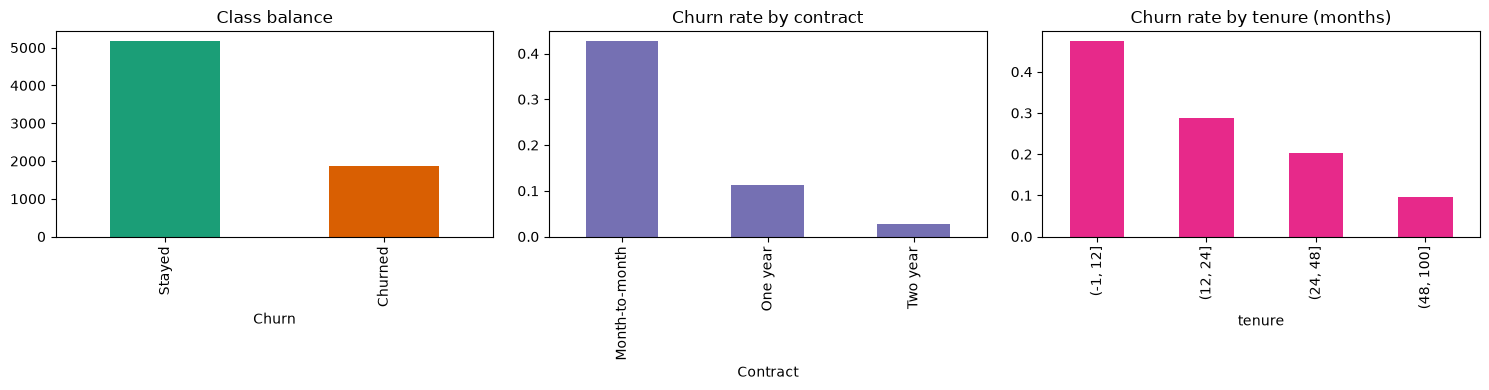

In [12]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
frame["Churn"].value_counts().rename({0: "Stayed", 1: "Churned"}).plot.bar(ax=axes[0], color=["#1b9e77", "#d95f02"])
axes[0].set_title("Class balance")
raw.groupby("Contract")["Churn"].apply(lambda s: (s == "Yes").mean()).plot.bar(ax=axes[1], color="#7570b3")
axes[1].set_title("Churn rate by contract")
frame.groupby(pd.cut(frame["tenure"], [-1, 12, 24, 48, 100]))["Churn"].mean().plot.bar(ax=axes[2], color="#e7298a")
axes[2].set_title("Churn rate by tenure (months)")
plt.tight_layout()
plt.show()

## 3. Train

This runs the full pipeline: leakage check, model comparison with 5-fold cross-validation, RandomizedSearchCV tuning, probability calibration, threshold selection, hold-out evaluation, SHAP, model saving, MLflow tracking and report generation. It takes a few minutes.

In [13]:
import logging
from churnguard import train

logging.basicConfig(level=logging.INFO, format="%(asctime)s %(message)s", stream=sys.stdout, force=True)
results = train.run()
print("Model version:", results["tag"])

2026-10-31 16:15:27,789 Data ready: 7043 rows, churn rate 0.265
2026-10-31 16:15:27,872 Comparing candidate models with stratified 5-fold cross-validation
2026-10-31 16:16:06,319 Tuning XGBoost with RandomizedSearchCV
2026-10-31 16:17:12,684 Fitting calibrated final model and choosing the decision threshold
2026-10-31 16:17:37,154 Computing SHAP explanations
2026-10-31 16:17:47,777 MLflow tracking skipped: The filesystem tracking backend (e.g., './mlruns') is in maintenance mode and will not receive further updates. Please migrate to a database backend (e.g., 'sqlite:///mlflow.db') to access the latest MLflow features. The `mlflow migrate-filestore` tool migrates your existing data losslessly. See https://mlflow.org/docs/latest/self-hosting/migrate-from-file-store for migration guidance. If the filesystem backend is required for your workflow, set `MLFLOW_ALLOW_FILE_STORE=true` to opt out of this exception.
2026-10-31 16:17:47,779 Finished in 140 s. Hold-out recall 0.880, PR-AUC 0.658,

In [14]:
%pip install -r requirements.txt


Note: you may need to restart the kernel to use updated packages.


## 4. Results

In [15]:
comparison = pd.DataFrame(results["comparison"])
columns = ["model", "accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc", "f2_at_best_threshold"]
display(comparison[columns].round(3))
for statement in results["improvements"]:
    print("-", statement)

,model,accuracy,precision,recall,f1,roc_auc,pr_auc,f2_at_best_threshold
0,Majority baseline,0.735,0.000,0.000,0.000,0.500,0.265,0.000
1,Logistic Regression,0.752,0.522,0.792,0.629,0.848,0.669,0.749
2,Random Forest,0.778,0.563,0.718,0.631,0.844,0.659,0.746
3,XGBoost (default settings),0.781,0.570,0.704,0.630,0.846,0.667,0.744
4,XGBoost (raw features only),0.782,0.572,0.703,0.631,0.844,0.663,0.742


- Logistic Regression versus Majority baseline: PR-AUC +0.404, ROC-AUC +0.348, recall +0.792, F2 at best threshold +0.749 (fold standard deviation of the reference PR-AUC: 0.000). This is a meaningful improvement.
- Random Forest versus Majority baseline: PR-AUC +0.394, ROC-AUC +0.344, recall +0.718, F2 at best threshold +0.746 (fold standard deviation of the reference PR-AUC: 0.000). This is a meaningful improvement.
- XGBoost (default settings) versus Majority baseline: PR-AUC +0.402, ROC-AUC +0.346, recall +0.704, F2 at best threshold +0.744 (fold standard deviation of the reference PR-AUC: 0.000). This is a meaningful improvement.
- Random Forest versus Logistic Regression: PR-AUC -0.010, ROC-AUC -0.003, recall -0.074, F2 at best threshold -0.003 (fold standard deviation of the reference PR-AUC: 0.017). This is not a meaningful improvement.
- XGBoost (default settings) versus Logistic Regression: PR-AUC -0.002, ROC-AUC -0.002, recall -0.088, F2 at best threshold -0.004 (fold standa

In [16]:
print("Chosen threshold:", round(results["threshold"]["value"], 2))
display(pd.DataFrame(results["threshold"]["table"]).round(3))
print("Best hyperparameters:", results["tuning"]["best_params"])

Chosen threshold: 0.13


,threshold,precision,recall,f1,f2,flagged_share
0,0.15,0.474,0.868,0.613,0.744,0.485
1,0.20,0.513,0.809,0.628,0.726,0.418
2,0.25,0.553,0.765,0.642,0.710,0.367
3,0.30,0.578,0.700,0.633,0.672,0.322
4,0.35,0.609,0.661,0.634,0.650,0.288
5,0.40,0.633,0.618,0.625,0.621,0.259
6,0.50,0.672,0.523,0.588,0.547,0.207
7,0.60,0.712,0.412,0.522,0.450,0.154


Best hyperparameters: {'colsample_bytree': np.float64(0.9868777594207296), 'gamma': np.float64(0.46554268086060846), 'learning_rate': np.float64(0.013118424770919554), 'max_depth': 4, 'min_child_weight': 7, 'n_estimators': 393, 'reg_lambda': np.float64(4.446862319918233), 'scale_pos_weight': np.float64(1.1161260317999944), 'subsample': np.float64(0.8430179407605753)}


In [17]:
holdout = results["holdout"]
baseline = results["baseline_holdout"]
keys = ["accuracy", "precision", "recall", "f1", "f2", "roc_auc", "pr_auc", "brier"]
display(pd.DataFrame({"Majority baseline": {k: baseline[k] for k in keys}, "ChurnGuard": {k: holdout[k] for k in keys}}).round(3))
print("Confusion matrix (rows: actual, columns: predicted)")
display(pd.DataFrame([[holdout["tn"], holdout["fp"]], [holdout["fn"], holdout["tp"]]], index=["Actually stayed", "Actually churned"], columns=["Predicted stay", "Predicted churn"]))
display(pd.DataFrame(holdout["classification_report"]).T.round(3))

,Majority baseline,ChurnGuard
accuracy,0.735,0.692
precision,0.000,0.458
recall,0.000,0.880
f1,0.000,0.603
f2,0.000,0.743
roc_auc,0.500,0.848
pr_auc,0.265,0.658
brier,0.265,0.136


Confusion matrix (rows: actual, columns: predicted)


,Predicted stay,Predicted churn
Actually stayed,646,389
Actually churned,45,329


,precision,recall,f1-score,support
No churn,0.935,0.624,0.749,1035.000
Churn,0.458,0.880,0.603,374.000
accuracy,0.692,0.692,0.692,0.692
macro avg,0.697,0.752,0.676,1409.000
weighted avg,0.808,0.692,0.710,1409.000


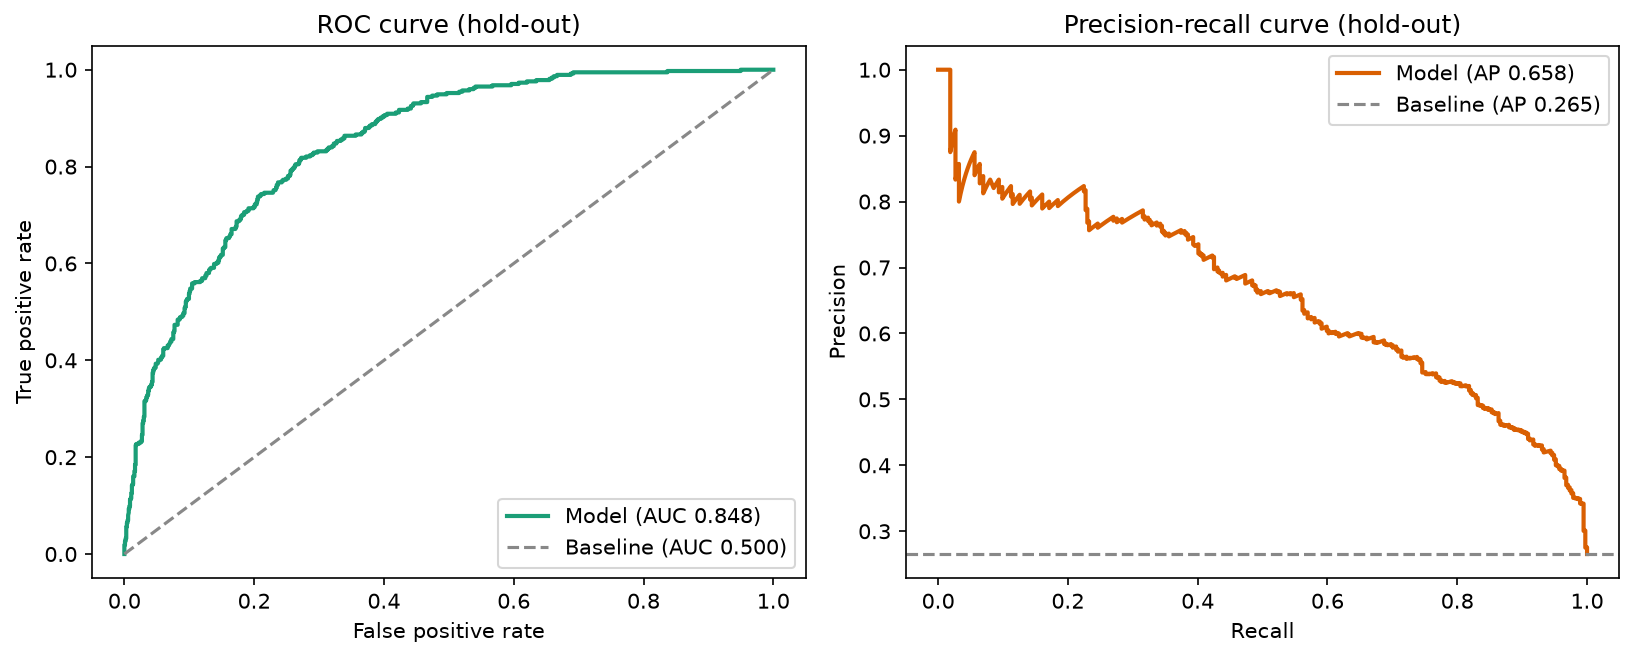

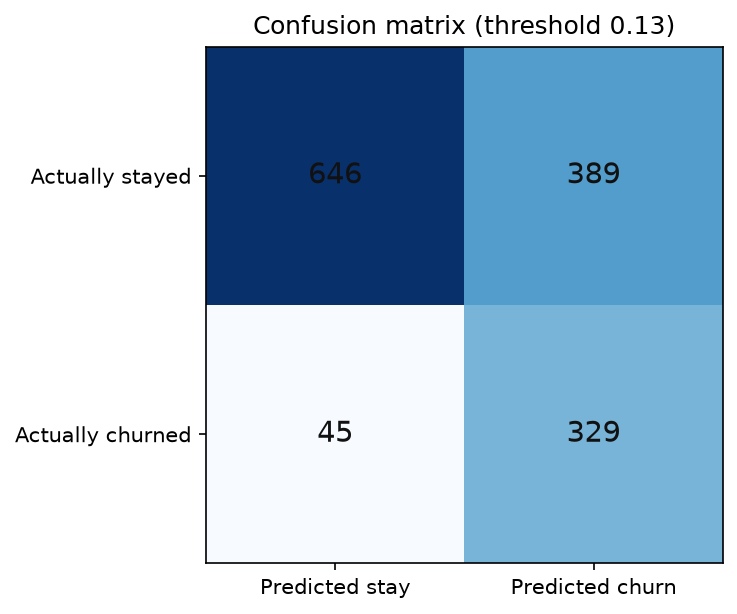

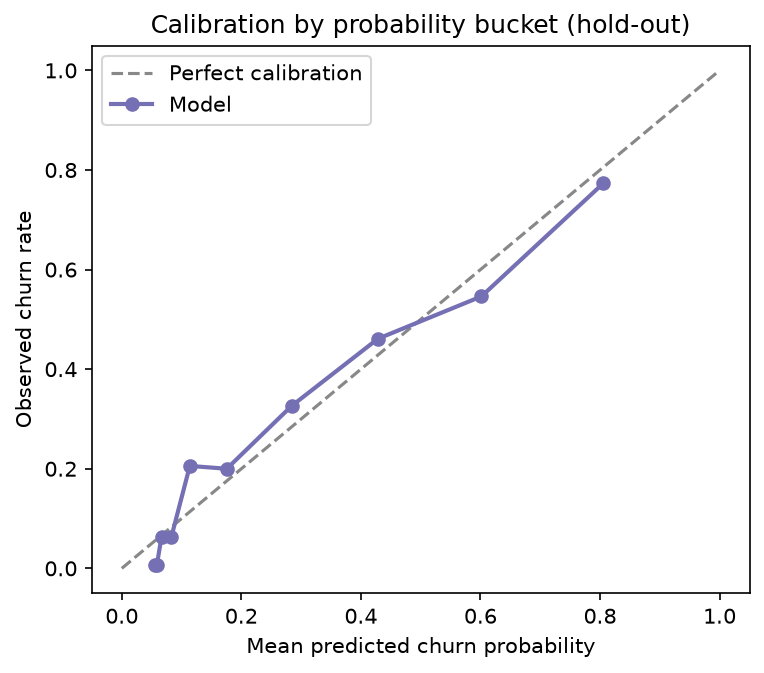

Expected calibration error: 0.04


,customers,mean_predicted,observed_rate,min_probability,max_probability,gap
0,141,0.055,0.007,0.054,0.056,0.048
1,141,0.059,0.007,0.056,0.062,0.052
2,141,0.067,0.064,0.062,0.073,0.003
3,141,0.083,0.064,0.073,0.095,0.019
4,141,0.114,0.206,0.095,0.134,0.092
5,140,0.176,0.200,0.135,0.225,0.024
6,141,0.284,0.326,0.226,0.346,0.042
7,141,0.428,0.461,0.347,0.520,0.033
8,141,0.602,0.546,0.521,0.676,0.055
9,141,0.805,0.773,0.677,0.896,0.032


In [18]:
from IPython.display import Image, display

for name in ["roc_pr_curves.png", "confusion_matrix.png", "calibration.png"]:
    display(Image(filename=os.path.join("reports", name)))
print("Expected calibration error:", round(results["calibration"]["summary"]["expected_calibration_error"], 4))
display(pd.DataFrame(results["calibration"]["table"]).round(3))

## 5. Error analysis and explanations

In [19]:
errors = results["error_analysis"]
for finding in errors["findings"]:
    print("-", finding)
for title, rows in errors["tables"].items():
    print()
    print("By", title)
    display(pd.DataFrame(rows).round(3))

- Systematic weakness (missed churners): in the segment Internet service = No the model misses 52.0% of churners (13 of 25), against 12.0% overall.
- Systematic weakness (false alarms): in the segment Contract = Month-to-month 74.8% of loyal customers are flagged (332 of 444), against 37.6% overall.

By Contract


,segment,customers,churners,false_negatives,fn_rate,non_churners,false_positives,fp_rate
0,Month-to-month,773,329,20,0.061,444,332,0.748
1,One year,300,36,16,0.444,264,52,0.197
2,Two year,336,9,9,1.000,327,5,0.015



By Tenure bucket


,segment,customers,churners,false_negatives,fn_rate,non_churners,false_positives,fp_rate
0,0-12,449,215,14,0.065,234,160,0.684
1,13-24,206,60,2,0.033,146,84,0.575
2,25-48,304,64,15,0.234,240,80,0.333
3,49+,450,35,14,0.400,415,65,0.157



By Internet service


,segment,customers,churners,false_negatives,fn_rate,non_churners,false_positives,fp_rate
0,DSL,484,97,20,0.206,387,124,0.320
1,Fiber optic,613,252,12,0.048,361,240,0.665
2,No,312,25,13,0.520,287,25,0.087



By Payment method


,segment,customers,churners,false_negatives,fn_rate,non_churners,false_positives,fp_rate
0,Bank transfer (automatic),300,57,13,0.228,243,52,0.214
1,Credit card (automatic),309,51,10,0.196,258,65,0.252
2,Electronic check,474,206,11,0.053,268,192,0.716
3,Mailed check,326,60,11,0.183,266,80,0.301


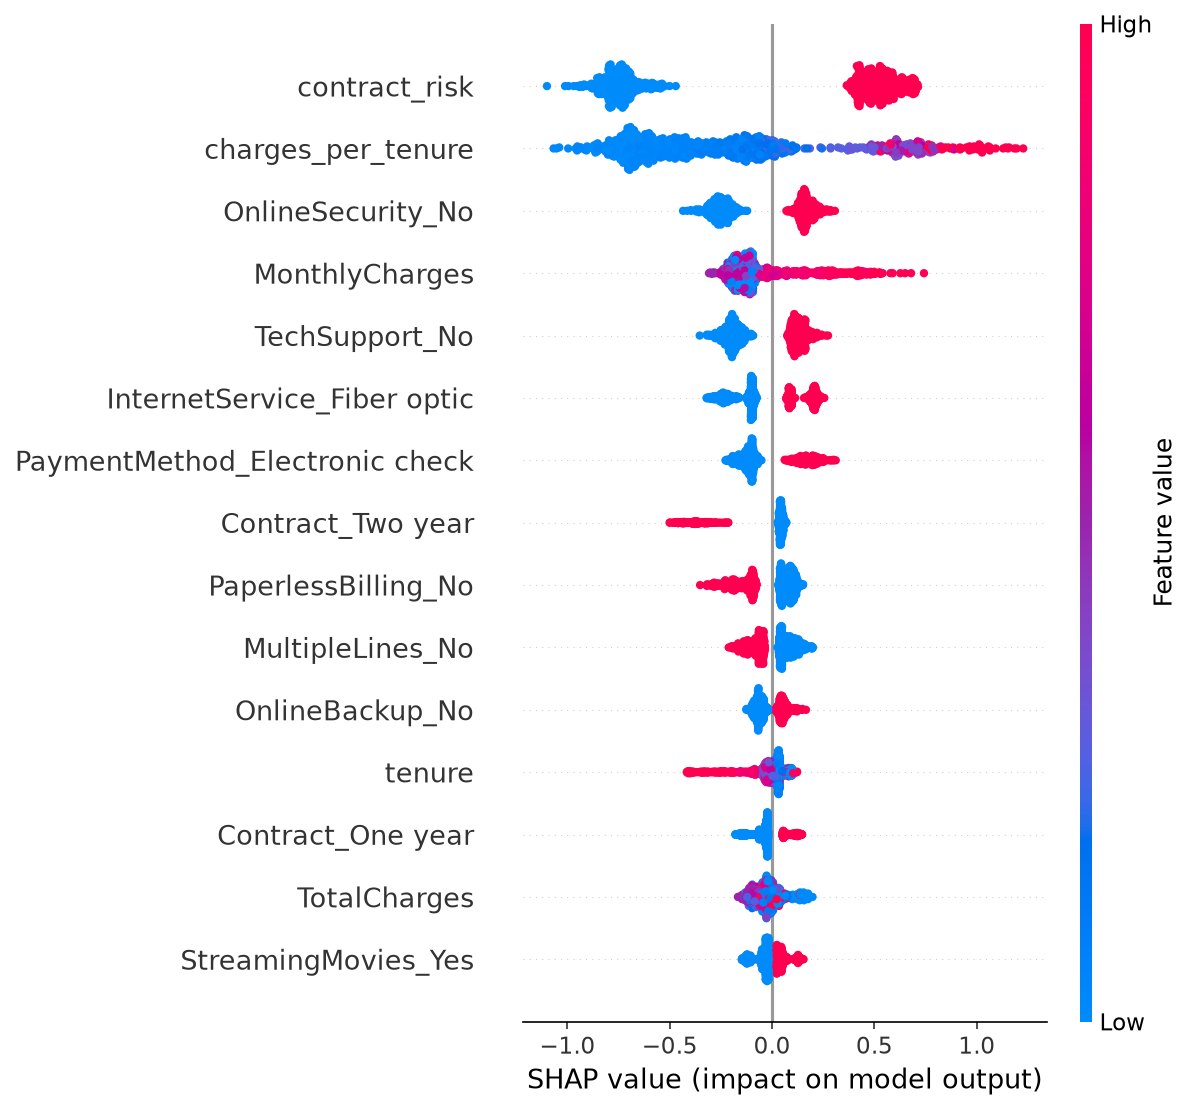

,feature,source,mean_abs_contribution
0,Month-to-month contract,contract_risk,0.6268
1,Monthly charges relative to tenure,charges_per_tenure,0.4862
2,Online security,OnlineSecurity,0.2139
3,Monthly charges,MonthlyCharges,0.1688
4,Internet service,InternetService,0.1687
5,Tech support,TechSupport,0.1687
6,Contract type,Contract,0.1502
7,Payment method,PaymentMethod,0.1496
8,Paperless billing,PaperlessBilling,0.1117
9,Multiple lines,MultipleLines,0.0885


In [20]:
display(Image(filename=os.path.join("reports", "shap_summary.png")))
display(pd.DataFrame(results["importance"]).head(12).round(4))

In [21]:
for example in results["local_examples"]:
    print(example["case"], "| actual churn:", example["actual_churn"], "| probability:", example["probability"], "| decision:", example["predicted_label"])
    for driver in example["drivers"]:
        print("   -", driver["explanation"])
    print()

High-risk churner correctly flagged | actual churn: Yes | probability: 0.896 | decision: Yes
   - Monthly charges relative to tenure (42.52) raises the predicted churn risk.
   - Month-to-month contract (yes) raises the predicted churn risk.
   - Online security (No) raises the predicted churn risk.

Loyal customer correctly cleared | actual churn: No | probability: 0.0542 | decision: No
   - Month-to-month contract (no) lowers the predicted churn risk.
   - Monthly charges relative to tenure (0.33) lowers the predicted churn risk.
   - Contract type (Two year) lowers the predicted churn risk.

Borderline customer close to the threshold | actual churn: No | probability: 0.1298 | decision: No
   - Month-to-month contract (yes) raises the predicted churn risk.
   - Monthly charges relative to tenure (2.05) lowers the predicted churn risk.
   - Internet service (DSL) lowers the predicted churn risk.

Hard case: churner the model missed | actual churn: Yes | probability: 0.055 | decision: 

## 6. API demo

Starts the FastAPI backend inside this notebook and sends a real prediction request with the API key.

In [22]:
import time, requests

env = dict(os.environ, CHURNGUARD_API_KEY="colab-demo-key")
server = subprocess.Popen(
    [sys.executable, "-m", "uvicorn", "app.main:app", "--host", "127.0.0.1", "--port", "8000"],
    env=env,
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL,
)

for _ in range(60):
    try:
        if requests.get("http://127.0.0.1:8000/health", timeout=2).status_code == 200:
            break
    except requests.RequestException:
        pass
    time.sleep(1)

print(requests.get("http://127.0.0.1:8000/health").json())

{'status': 'ok', 'model_version': '20261031_xgb-calibrated', 'threshold': 0.13}


In [23]:
import json

customer = dict(config.SAMPLE_CUSTOMER)
headers = {"X-API-Key": "colab-demo-key"}

started = time.perf_counter()
response = requests.post("http://127.0.0.1:8000/predict", json=customer, headers=headers)
elapsed = time.perf_counter() - started
print("Status:", response.status_code, "| latency:", round(elapsed, 3), "seconds")
print(json.dumps(response.json(), indent=2))

wrong = requests.post("http://127.0.0.1:8000/predict", json=customer, headers={"X-API-Key": "wrong"})
print("Wrong key status:", wrong.status_code)

Status: 200 | latency: 0.17 seconds
{
  "probability": 0.7182,
  "label": "Yes",
  "risk_level": "high",
  "threshold": 0.13,
  "top_drivers": [
    {
      "feature": "Monthly charges relative to tenure",
      "value": "14.93",
      "impact": 0.6251,
      "direction": "increases risk",
      "explanation": "Monthly charges relative to tenure (14.93) raises the predicted churn risk."
    },
    {
      "feature": "Month-to-month contract",
      "value": "yes",
      "impact": 0.5833,
      "direction": "increases risk",
      "explanation": "Month-to-month contract (yes) raises the predicted churn risk."
    },
    {
      "feature": "Internet service",
      "value": "DSL",
      "impact": -0.2563,
      "direction": "decreases risk",
      "explanation": "Internet service (DSL) lowers the predicted churn risk."
    }
  ],
  "summary": "Monthly charges relative to tenure (14.93) raises the predicted churn risk. Month-to-month contract (yes) raises the predicted churn risk. Interne

In [24]:
print(open("logs/predictions.jsonl").read().strip().splitlines()[-1])

{"timestamp": "2026-10-31T11:18:01", "request_id": "a4d305ac43ea464689b033745d762fc0", "endpoint": "/predict", "model_version": "20261031_xgb-calibrated", "inputs": {"gender": "Female", "SeniorCitizen": 0, "Partner": "Yes", "Dependents": "No", "tenure": 1, "PhoneService": "No", "MultipleLines": "No phone service", "InternetService": "DSL", "OnlineSecurity": "No", "OnlineBackup": "Yes", "DeviceProtection": "No", "TechSupport": "No", "StreamingTV": "No", "StreamingMovies": "No", "Contract": "Month-to-month", "PaperlessBilling": "Yes", "PaymentMethod": "Electronic check", "MonthlyCharges": 29.85, "TotalCharges": 29.85}, "probability": 0.7182, "label": "Yes", "risk_level": "high", "top_drivers": ["Monthly charges relative to tenure (14.93) raises the predicted churn risk.", "Month-to-month contract (yes) raises the predicted churn risk.", "Internet service (DSL) lowers the predicted churn risk."], "latency_ms": 146.71}


In [25]:
server.terminate()
server.wait()

1

## 7. Tests

In [26]:
!python -m pytest -q

..............................                                           [100%]
30 passed in 10.73s


## 8. Extras

Retraining on newly appended data, a LightGBM comparison, and viewing experiments in MLflow.

In [27]:
extra = frame.sample(200, random_state=1).copy()
extra["customerID"] = [f"NEW-{i:04d}" for i in range(len(extra))]
extra["Churn"] = extra["Churn"].map({1: "Yes", 0: "No"})
extra["TotalCharges"] = extra["TotalCharges"].astype(str)
extra[raw.columns].to_csv("data/new/demo_new_customers.csv", index=False)
!python -m churnguard.retrain --search-iter 5 --no-mlflow

Base rows: 7043. New files: 1. Combined unique customers: 7243.
2026-10-31 16:18:24,785 INFO Data ready: 7243 rows, churn rate 0.265
2026-10-31 16:18:24,869 INFO Comparing candidate models with stratified 5-fold cross-validation
2026-10-31 16:18:59,726 INFO Tuning XGBoost with RandomizedSearchCV
2026-10-31 16:19:14,250 INFO Fitting calibrated final model and choosing the decision threshold
2026-10-31 16:19:38,882 INFO Computing SHAP explanations
2026-10-31 16:19:49,571 INFO Finished in 85 s. Hold-out recall 0.901, PR-AUC 0.644, ROC-AUC 0.845 at threshold 0.12
New model version: 20261031_161824_retrain
Hold-out recall 0.901 | PR-AUC 0.644 | ROC-AUC 0.845


In [28]:
!python -m churnguard.boosting_comparison

                   model  accuracy  recall  roc_auc  pr_auc  f2_at_best_threshold
         XGBoost (tuned)    0.8062  0.5625   0.8503  0.6737                0.7485
LightGBM (same settings)    0.8049  0.5572   0.8500  0.6724                0.7477
Saved to C:\Users\HP 840 G5\OneDrive\Desktop\zaid .html\ChurnGuard\reports\boosting_comparison.csv


In [29]:
print(sorted(os.listdir("models")))
print(open("models/latest.json").read())

['.gitkeep', 'churn_pipeline_20261031_161824_retrain.joblib', 'churn_pipeline_20261031_161824_retrain.json', 'churn_pipeline_20261031_161824_retrain.skops', 'churn_pipeline_20261031_xgb-calibrated.joblib', 'churn_pipeline_20261031_xgb-calibrated.json', 'churn_pipeline_20261031_xgb-calibrated.skops', 'latest.json', 'regression_case.json']
{
  "tag": "20261031_161824_retrain",
  "joblib_file": "churn_pipeline_20261031_161824_retrain.joblib",
  "skops_file": "churn_pipeline_20261031_161824_retrain.skops",
  "threshold": 0.12,
  "trained_at": "2026-10-31T16:19:49",
  "versions": {
    "python": "3.14.6",
    "scikit-learn": "1.9.0",
    "pandas": "3.0.3",
    "numpy": "2.4.6",
    "joblib": "1.5.3",
    "xgboost": "3.4.1",
    "shap": "0.54.1",
    "skops": "0.16.0",
    "mlflow": "3.17.2",
    "lightgbm": "4.7.0"
  },
  "summary": {
    "best_params": {
      "colsample_bytree": 0.9868777594207296,
      "gamma": 0.46554268086060846,
      "learning_rate": 0.013118424770919554,
      "max

In [31]:
import zipfile, os
with zipfile.ZipFile("ChurnGuard_results.zip", "w") as z:
    for folder in ["models", "reports"]:
        for root, _, names in os.walk(folder):
            for n in names:
                z.write(os.path.join(root, n))
    z.write("MODEL_CARD.md")
    z.write("EVALUATION_REPORT.md")